# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name: Saba Noor**
- **Roll No: 023-24-0278**
- **Section: H**
- **Date: 11/11/2026**

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [7]:
# Task 1.1
def weighted_sum(w,x,b):
    return sum(wi*xi for wi,xi in zip(w,x)) + b

def step_function(z):
    return 1 if z>=0 else 0

def predict(w,x,b):
    return step_function(weighted_sum(w,x,b))

w=[0.6,0.8]
x=[2,3]
b=-2

print(predict(w,x,b))

print("--------------")
w=[1,-0.5]
b=0.5
inputs=[[1,1],[2,1],[0,3]]

for x in inputs:
    print(predict(w,x,b))

1
--------------
1
1
0


### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [8]:
# Task 1.2
data=[
    ([0,0],0),
    ([0,1],0),
    ([1,0],0),
    ([1,1],1)
]

w=[0.2,-0.1]
b=0
eta=0.1

mistakes=0

for x, y in data:
    z=sum(wi*xi for wi,xi in zip(w,x))+b
    y_hat=1 if z>=0 else 0
    e=y-y_hat

    w[0]=w[0]+eta*e*x[0]
    w[1]=w[1]+eta*e*x[1]
    b=b+eta*e

    if e!=0:
        mistakes+=1

    print("Input:", x)
    print("Actual:", y)
    print("z:", round(z, 2))
    print("Prediction:", y_hat)
    print("Error:", e)
    print("Updated weights:", w)
    print("Updated bias:", round(b, 2))
    print("-------------------")

if(mistakes==0):
    print("Converged!")
else:
    print("Keep training")

print("Final weights:", w)
print("Final bias:", b)
print("Number of mistakes:", mistakes)

if mistakes == 0:
    print("Converged!")
else:
    print("Keep training.")

Input: [0, 0]
Actual: 0
z: 0.0
Prediction: 1
Error: -1
Updated weights: [0.2, -0.1]
Updated bias: -0.1
-------------------
Input: [0, 1]
Actual: 0
z: -0.2
Prediction: 0
Error: 0
Updated weights: [0.2, -0.1]
Updated bias: -0.1
-------------------
Input: [1, 0]
Actual: 0
z: 0.1
Prediction: 1
Error: -1
Updated weights: [0.1, -0.1]
Updated bias: -0.2
-------------------
Input: [1, 1]
Actual: 1
z: -0.2
Prediction: 0
Error: 1
Updated weights: [0.2, 0.0]
Updated bias: -0.1
-------------------
Keep training
Final weights: [0.2, 0.0]
Final bias: -0.1
Number of mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [9]:
import numpy as np

def train_perceptron(X, y, eta=0.1, max_epochs=100):

    w = np.zeros(X.shape[1])
    b = 0

    mistakes = []

    for epoch in range(max_epochs):
        error_count = 0

        for x, target in zip(X, y):

            z = np.dot(w, x) + b

            y_hat = 1 if z >= 0 else 0

            e = target - y_hat

            if e != 0:
                w = w + eta * e * x
                b = b + eta * e
                error_count += 1

        mistakes.append(error_count)

        print("Epoch:", epoch + 1,
              "Mistakes:", error_count)

        if error_count == 0:
            print("Converged!")
            break

    return w, b, mistakes

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 1, 1, 1])

w, b, mistakes = train_perceptron(X, y)

print("Final weights:", w)
print("Final bias:", b)
print("Mistakes:", mistakes)


Epoch: 1 Mistakes: 2
Epoch: 2 Mistakes: 2
Epoch: 3 Mistakes: 1
Epoch: 4 Mistakes: 0
Converged!
Final weights: [0.1 0.1]
Final bias: -0.1
Mistakes: [2, 2, 1, 0]


### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

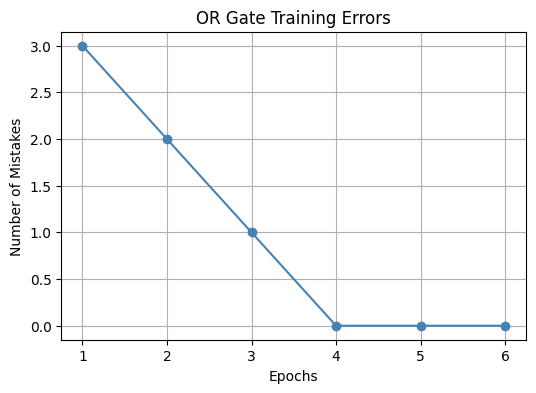

In [10]:
# Task 2.2
import numpy as np
import matplotlib.pyplot as plt

mistakes_or = [3, 2, 1, 0, 0, 0]

epochs = np.arange(1, len(mistakes_or) + 1)

plt.figure(figsize=(6, 4))
plt.plot(epochs, mistakes_or,
         marker='o', color='steelblue')

plt.xlabel("Epochs")
plt.ylabel("Number of Mistakes")
plt.title("OR Gate Training Errors")
plt.grid(True)

plt.show()

**Interpretation:** *your answer here*

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

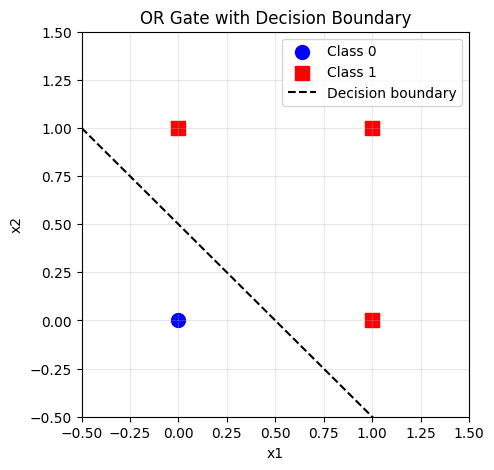

In [11]:
#Task 3.1
import numpy as np
import matplotlib.pyplot as plt

X_or = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_or = np.array([0, 1, 1, 1])

w_or = np.array([1.0, 1.0])
b_or = -0.5

def plot_boundary(ax, w, b, x_range=(-0.5, 1.5), **kwargs):

    kwargs.setdefault('color', 'black')
    kwargs.setdefault('linestyle', '--')
    kwargs.setdefault('label', 'Decision boundary')

    x1 = np.linspace(x_range[0], x_range[1], 100)

    if w[1] != 0:
        x2 = -(w[0] / w[1]) * x1 - b / w[1]
        ax.plot(x1, x2, **kwargs)

    elif w[0] != 0:
        ax.axvline(-b / w[0], **kwargs)


fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(
    X_or[y_or==0, 0],
    X_or[y_or==0, 1],
    c='blue', marker='o', s=100,
    label='Class 0'
)

ax.scatter(
    X_or[y_or==1, 0],
    X_or[y_or==1, 1],
    c='red', marker='s', s=100,
    label='Class 1'
)

plot_boundary(ax, w_or, b_or)

ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)

ax.set_title("OR Gate with Decision Boundary")
ax.set_xlabel("x1")
ax.set_ylabel("x2")

ax.legend()
ax.grid(alpha=0.3)

plt.show()


**Interpretation:** *This graph shows how an OR gate classifies inputs into two classes using a straight decision boundary. It demonstrates that whenever at least one input is 1, the output is 1; only when both inputs are 0, the output is 0, making OR a linearly separable problem.*

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

Epoch: 1 Mistakes: 2
Epoch: 2 Mistakes: 3
Epoch: 3 Mistakes: 1
Epoch: 4 Mistakes: 0
Converged!
With bias   : w = [0.1 0.1]  b = -0.2  epochs = 4  final mistakes = 0
Without bias: w = [0.1 0. ]  b = 0.0  epochs = 100  final mistakes = 2


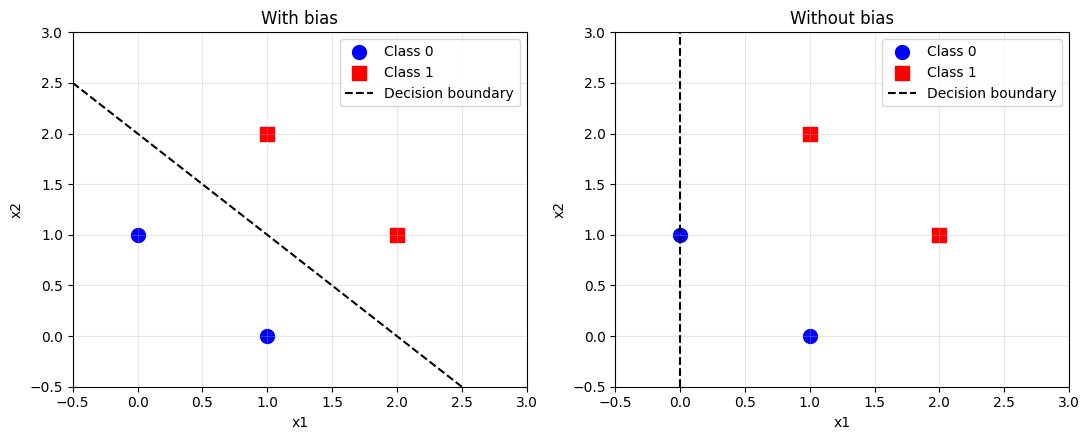

In [12]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.array(X, dtype=float)
    w = np.zeros(X.shape[1])
    b = 0.0                                # stays 0, never updated
    mistakes = []
    for epoch in range(max_epochs):
        count = 0
        for xi, yi in zip(X, y):
            y_hat = 1 if np.dot(w, xi) >= 0 else 0
            e = yi - y_hat
            if e != 0:
                w = w + eta * e * xi       # no bias update
                count += 1
        mistakes.append(count)
        if count == 0:
            break
    return w, b, mistakes

X32 = np.array([[1,0],[0,1],[2,1],[1,2]])
y32 = np.array([0, 0, 1, 1])

w_b,  b_b,  m_b  = train_perceptron(X32, y32)
w_nb, b_nb, m_nb = train_perceptron_nobias(X32, y32)

print("With bias   : w =", np.round(w_b, 3),  " b =", round(b_b, 3),  " epochs =", len(m_b),  " final mistakes =", m_b[-1])
print("Without bias: w =", np.round(w_nb, 3), " b =", b_nb,           " epochs =", len(m_nb), " final mistakes =", m_nb[-1])

fig = plt.figure(figsize=(11, 4.5))
for k, (w_, b_, title) in enumerate([(w_b, b_b, "With bias"), (w_nb, b_nb, "Without bias")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(X32[y32==0, 0], X32[y32==0, 1], c='blue', marker='o', s=100, label='Class 0')
    ax.scatter(X32[y32==1, 0], X32[y32==1, 1], c='red',  marker='s', s=100, label='Class 1')
    plot_boundary(ax, w_, b_, x_range=(-0.5, 3))
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** *The perceptron with bias successfully converges, and its decision boundary correctly separates the classes. However, the perceptron without bias fails to converge even after 100 epochs because its decision boundary must pass through the origin. No line passing through the origin can correctly separate these data points. Adding a bias allows the decision boundary to shift away from the origin, making it possible to separate the classes*

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epoch: 1 Mistakes: 3
Epoch: 2 Mistakes: 3
Epoch: 3 Mistakes: 4
Epoch: 4 Mistakes: 4
Epoch: 5 Mistakes: 4
Epoch: 6 Mistakes: 4
Epoch: 7 Mistakes: 4
Epoch: 8 Mistakes: 4
Epoch: 9 Mistakes: 4
Epoch: 10 Mistakes: 4
Epoch: 11 Mistakes: 4
Epoch: 12 Mistakes: 4
Epoch: 13 Mistakes: 4
Epoch: 14 Mistakes: 4
Epoch: 15 Mistakes: 4
Epoch: 16 Mistakes: 4
Epoch: 17 Mistakes: 4
Epoch: 18 Mistakes: 4
Epoch: 19 Mistakes: 4
Epoch: 20 Mistakes: 4
Epoch: 21 Mistakes: 4
Epoch: 22 Mistakes: 4
Epoch: 23 Mistakes: 4
Epoch: 24 Mistakes: 4
Epoch: 25 Mistakes: 4
Epoch: 26 Mistakes: 4
Epoch: 27 Mistakes: 4
Epoch: 28 Mistakes: 4
Epoch: 29 Mistakes: 4
Epoch: 30 Mistakes: 4
Epoch: 31 Mistakes: 4
Epoch: 32 Mistakes: 4
Epoch: 33 Mistakes: 4
Epoch: 34 Mistakes: 4
Epoch: 35 Mistakes: 4
Epoch: 36 Mistakes: 4
Epoch: 37 Mistakes: 4
Epoch: 38 Mistakes: 4
Epoch: 39 Mistakes: 4
Epoch: 40 Mistakes: 4
Epoch: 41 Mistakes: 4
Epoch: 42 Mistakes: 4
Epoch: 43 Mistakes: 4
Epoch: 44 Mistakes: 4
Epoch: 45 Mistakes: 4
Epoch: 46 Mistakes:

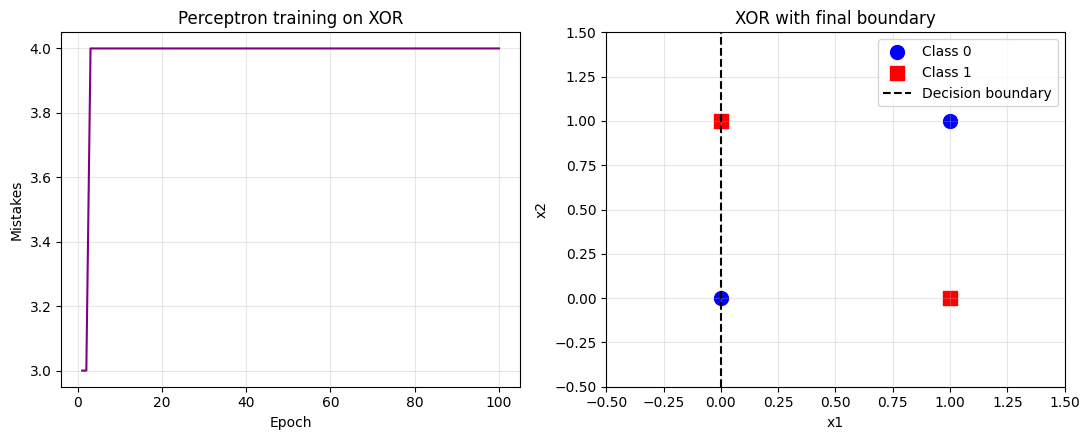

In [13]:
# Task 4.1
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])

w_x, b_x, m_x = train_perceptron(X_xor, y_xor, eta=0.1, max_epochs=100)
print("Epochs run      :", len(m_x))
print("Final mistakes  :", m_x[-1])
print("w =", np.round(w_x, 3), " b =", round(b_x, 3))

fig = plt.figure(figsize=(11, 4.5))

ax1 = plt.subplot(1, 2, 1)
ax1.plot(range(1, len(m_x)+1), m_x, color='purple')
ax1.set_title("Perceptron training on XOR")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Mistakes")
ax1.grid(alpha=0.3)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_xor[y_xor==0, 0], X_xor[y_xor==0, 1], c='blue', marker='o', s=100, label='Class 0')
ax2.scatter(X_xor[y_xor==1, 0], X_xor[y_xor==1, 1], c='red',  marker='s', s=100, label='Class 1')
plot_boundary(ax2, w_x, b_x)
ax2.set_xlim(-0.5, 1.5); ax2.set_ylim(-0.5, 1.5)
ax2.set_title("XOR with final boundary")
ax2.set_xlabel("x1"); ax2.set_ylabel("x2")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** *This graph demonstrates that a single-layer perceptron cannot correctly learn the XOR gate because its classes cannot be separated using one straight decision boundary. As a result, training mistakes do not reach zero, showing that XOR is a non-linearly separable problem.*

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [14]:
# Task 4.2
def check_xor(w, b):
    return (np.dot(w, [0,0]) + b <  0 and
            np.dot(w, [0,1]) + b >= 0 and
            np.dot(w, [1,0]) + b >= 0 and
            np.dot(w, [1,1]) + b <  0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)

passing = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]

print("Triples passing:", len(passing), "out of 10000")
if len(passing) == 0:
    print("No solution found")
else:
    print("First passing triple:", passing[0])

Triples passing: 0 out of 10000
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [15]:
# Task 5.1
X = iris.data[:, (2, 3)]
y = (iris.target == 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

clf = Perceptron(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred, target_names=["Rest", "Setosa"]))
print("coef_     :", clf.coef_)
print("intercept_:", clf.intercept_)

Accuracy: 1.0

Confusion matrix:
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_     : [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** *your answer here*

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

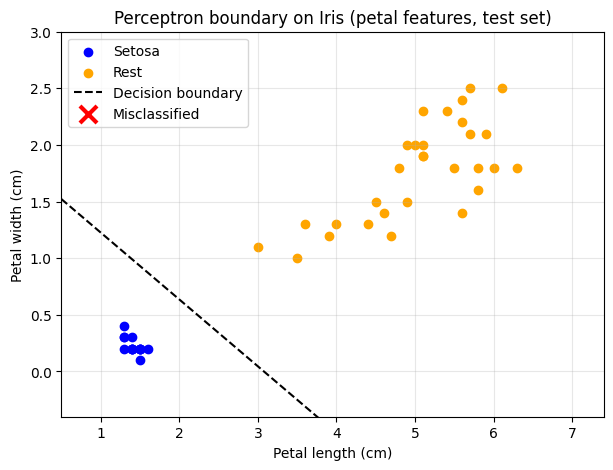

Misclassified test points: 0 out of 45


In [16]:
# Task 5.2
w5 = clf.coef_[0]
b5 = clf.intercept_[0]
mis = y_pred != y_test

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1], c='blue',   label='Setosa')
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1], c='orange', label='Rest')
plot_boundary(ax, w5, b5, x_range=(X[:,0].min()-0.5, X[:,0].max()+0.5))
ax.scatter(X_test[mis, 0], X_test[mis, 1], c='red', marker='x', s=150, linewidths=3,
           label='Misclassified', zorder=5)          # plotted last
ax.set_xlim(X[:,0].min()-0.5, X[:,0].max()+0.5)
ax.set_ylim(X[:,1].min()-0.5, X[:,1].max()+0.5)
ax.set_title("Perceptron boundary on Iris (petal features, test set)")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print("Misclassified test points:", mis.sum(), "out of", len(y_test))

**Interpretation:** *This graph shows how the perceptron separates Iris Setosa flowers from the remaining classes using petal length and petal width. The red crosses represent misclassified test points, showing where the model makes incorrect predictions.*

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [17]:
# Task 5.3
import pandas as pd

rows = []
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(eta0=eta0, random_state=42)
    m.fit(X_train, y_train)
    acc = accuracy_score(y_test, m.predict(X_test))
    rows.append({"eta0": eta0, "accuracy": acc, "n_iter_": m.n_iter_,
                 "coef_": np.round(m.coef_[0], 4), "intercept_": np.round(m.intercept_[0], 4)})

table = pd.DataFrame(rows)
print(table.to_string(index=False))

  eta0  accuracy  n_iter_              coef_  intercept_
 0.001       1.0        6 [-0.0013, -0.0022]       0.004
 0.100       1.0        7     [-0.13, -0.22]       0.400
10.000       1.0        7     [-13.0, -22.0]      40.000


**Interpretation:**  *All three eta0 values achieve an accuracy of 1.0, meaning the predictions remain unchanged. The number of iterations is also very similar (6, 7, and 7). The coefficient vectors point in the same direction, but their magnitudes change according to eta0. For eta0 = 0.001, the weights and bias are [-0.0013, -0.0022] and 0.004. For eta0 = 0.1, they are [-0.13, -0.22] and 0.4, while for eta0 = 10.0, they are [-13, -22] and 40. Each set is exactly 100 times larger than the previous one.

This happens because training starts with w = 0, and each weight update is proportional to eta multiplied by the same sequence of (error × input) values. Therefore, changing eta0 only scales the weights and bias without changing their direction. As a result, the sign of w·x + b remains unchanged, so the step function produces the same predictions for all three learning rates (Slide 19).*

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [18]:
# Task 6.1
X6 = iris.data
y6 = iris.target
X6_train, X6_test, y6_train, y6_test = train_test_split(
    X6, y6, test_size=0.3, random_state=42, stratify=y6)

clf6 = Perceptron(random_state=42, max_iter=1000)
clf6.fit(X6_train, y6_train)
y6_pred = clf6.predict(X6_test)

print("Classification report:\n", classification_report(y6_test, y6_pred, target_names=iris.target_names))
print("Confusion matrix:\n", confusion_matrix(y6_test, y6_pred))
print("coef_.shape:", clf6.coef_.shape)

Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]
coef_.shape: (3, 4)


C:\Users\sabaj\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sabaj\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\sabaj\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

**Interpretation:** *This task trains a perceptron model on the Iris dataset to classify flowers into three species: Setosa, Versicolor, and Virginica. The classification report and confusion matrix evaluate the model's performance, while coef_.shape shows the dimensions of the learned weights.*

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [19]:
# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200)
lr.fit(X6_train, y6_train)
y6_lr = lr.predict(X6_test)

comparison = pd.DataFrame({
    "Model": ["Perceptron", "Logistic Regression"],
    "Accuracy": [accuracy_score(y6_test, y6_pred), accuracy_score(y6_test, y6_lr)],
    "Macro-F1": [f1_score(y6_test, y6_pred, average='macro'), f1_score(y6_test, y6_lr, average='macro')]
})
print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Macro-F1
         Perceptron    0.6667    0.5499
Logistic Regression    0.9333    0.9333


**Interpretation:** *This task compares the performance of Perceptron and Logistic Regression on the Iris dataset using Accuracy and Macro-F1 scores. The comparison helps identify which model performs better in classifying the three flower species.*

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

z=(0.5)(1)+(-0.3)(2)+0.2

z=0.1

y_pred=1

error=0-1

error=-1

w_1=0.5+0.1(-1)(1)=0.4

w_2=-0.3+0.1(-1)(2)=-0.5

b=0.2+0.1(-1)=0.1

w1=0.4

w2=0.5

b=0.1

**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

z=w1x1+w2x2+b

y_pred=1 

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

a)
b<0

w_1+b>=0

w_2+b>=0

w_1+w_2+b<0

w_1+w_2+2b>=0


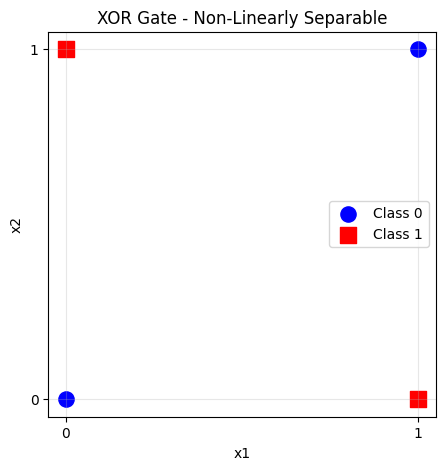

In [20]:
# b)
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([0, 1, 1, 0])

plt.figure(figsize=(5, 5))

plt.scatter(X[y==0, 0], X[y==0, 1],
            color='blue', marker='o', s=120, label='Class 0')

plt.scatter(X[y==1, 0], X[y==1, 1],
            color='red', marker='s', s=120, label='Class 1')

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("XOR Gate - Non-Linearly Separable")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

c) We can solve the XOR problem by using a Multi-Layer Perceptron (MLP) with at least one hidden layer and a non-linear activation function. This allows the model to learn more complex decision boundaries.

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [21]:
from sklearn.datasets import load_iris

iris = load_iris()

y = iris.target

X_new = iris.data[:, [0, 2, 3]]
X_new = iris.data[:, [0, 2, 3]]

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y, test_size=0.3, random_state=42, stratify=y
)

clf_new = Perceptron(random_state=42, max_iter=1000)
clf_new.fit(X_train_new, y_train_new)

y_pred_new = clf_new.predict(X_test_new)

print("Accuracy:", accuracy_score(y_test_new, y_pred_new))
print("Macro-F1:", f1_score(y_test_new, y_pred_new, average='macro'))

Accuracy: 0.6666666666666666
Macro-F1: 0.5334281650071123


In [22]:
# Q4
y_q4 = (iris.target == 0).astype(int)

def run_features(cols):
    Xf = iris.data[:, cols]
    Xtr, Xte, ytr, yte = train_test_split(Xf, y_q4, test_size=0.3, random_state=42, stratify=y_q4)
    m = Perceptron(random_state=42).fit(Xtr, ytr)
    p = m.predict(Xte)
    return accuracy_score(yte, p), f1_score(yte, p, average='macro')

acc2, f12 = run_features((2, 3))
acc3, f13 = run_features((0, 2, 3))

print(pd.DataFrame({
    "Features": ["(2,3) petal only", "(0,2,3) + sepal length"],
    "Accuracy": [acc2, acc3],
    "Macro-F1": [f12, f13]
}).round(4).to_string(index=False))

              Features  Accuracy  Macro-F1
      (2,3) petal only       1.0       1.0
(0,2,3) + sepal length       1.0       1.0


The comparison shows whether adding sepal length improves the Iris classification model. Higher accuracy and Macro-F1 scores for the three-feature model indicate that the extra feature helps improve classification performance

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Epoch: 1 Mistakes: 33
Epoch: 2 Mistakes: 30
Epoch: 3 Mistakes: 33
Epoch: 4 Mistakes: 32
Epoch: 5 Mistakes: 29
Epoch: 6 Mistakes: 29
Epoch: 7 Mistakes: 35
Epoch: 8 Mistakes: 29
Epoch: 9 Mistakes: 31
Epoch: 10 Mistakes: 31
Epoch: 11 Mistakes: 33
Epoch: 12 Mistakes: 31
Epoch: 13 Mistakes: 35
Epoch: 14 Mistakes: 34
Epoch: 15 Mistakes: 36
Epoch: 16 Mistakes: 33
Epoch: 17 Mistakes: 33
Epoch: 18 Mistakes: 33
Epoch: 19 Mistakes: 30
Epoch: 20 Mistakes: 32
Epoch: 21 Mistakes: 32
Epoch: 22 Mistakes: 36
Epoch: 23 Mistakes: 37
Epoch: 24 Mistakes: 31
Epoch: 25 Mistakes: 33
Epoch: 26 Mistakes: 36
Epoch: 27 Mistakes: 30
Epoch: 28 Mistakes: 32
Epoch: 29 Mistakes: 34
Epoch: 30 Mistakes: 33
Epoch: 31 Mistakes: 34
Epoch: 32 Mistakes: 31
Epoch: 33 Mistakes: 33
Epoch: 34 Mistakes: 30
Epoch: 35 Mistakes: 32
Epoch: 36 Mistakes: 32
Epoch: 37 Mistakes: 36
Epoch: 38 Mistakes: 37
Epoch: 39 Mistakes: 31
Epoch: 40 Mistakes: 33
Epoch: 41 Mistakes: 36
Epoch: 42 Mistakes: 30
Epoch: 43 Mistakes: 32
Epoch: 44 Mistakes: 

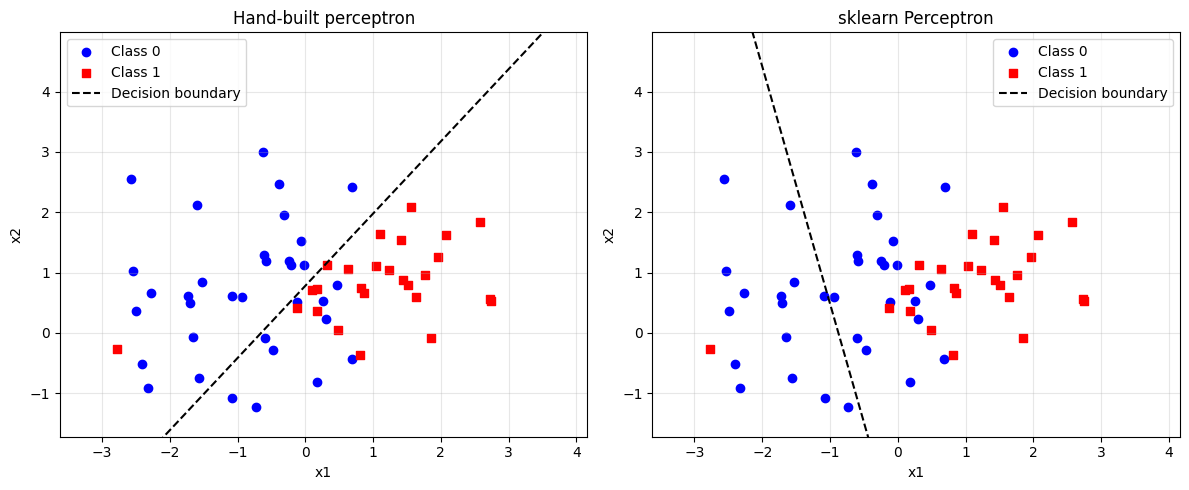

In [24]:
# Q5
from sklearn.datasets import make_classification

Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=100)
pred_h = (Xs_te @ w_h + b_h >= 0).astype(int)
acc_h = accuracy_score(ys_te, pred_h)

sk = Perceptron(eta0=0.1, random_state=42, max_iter=1000).fit(Xs_tr, ys_tr)
acc_s = accuracy_score(ys_te, sk.predict(Xs_te))

print(pd.DataFrame({
    "Model": ["Hand-built", "sklearn"],
    "Test accuracy": [acc_h, acc_s],
    "Epochs": [len(m_h), sk.n_iter_],
    "w": [np.round(w_h, 3), np.round(sk.coef_[0], 3)],
    "b": [round(b_h, 3), round(sk.intercept_[0], 3)]
}).to_string(index=False))

fig = plt.figure(figsize=(12, 5))
xr = (Xs[:,0].min()-0.5, Xs[:,0].max()+0.5)
for k, (w_, b_, title) in enumerate([(w_h, b_h, "Hand-built perceptron"),
                                      (sk.coef_[0], sk.intercept_[0], "sklearn Perceptron")], start=1):
    ax = plt.subplot(1, 2, k)
    ax.scatter(Xs_te[ys_te==0, 0], Xs_te[ys_te==0, 1], c='blue', marker='o', label='Class 0')
    ax.scatter(Xs_te[ys_te==1, 0], Xs_te[ys_te==1, 1], c='red',  marker='s', label='Class 1')
    plot_boundary(ax, w_, b_, x_range=xr)
    ax.set_xlim(*xr); ax.set_ylim(Xs[:,1].min()-0.5, Xs[:,1].max()+0.5)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The comparison shows that both the hand-built and sklearn perceptrons learn a decision boundary to classify the two classes. Their test accuracy, weights, and number of epochs help evaluate their performance, with any differences resulting from their training and update methods.